# Citi Bike — Seasonal Naive and Moving Average
Clean notebook: no prior outputs. Uses `modeling_dataset.parquet`. One-hour-ahead rolling evaluation: predictions for hour *t* use observed demand only through hour *t−1*.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("modeling_dataset.parquet")
OUT = Path("seasonal_baseline_results")
OUT.mkdir(exist_ok = True)
MAX_STATIONS = 3  # Set to None for every station
TEST_HOURS = 168  # Last seven days of each station
STATION_COL = None  # Set manually if automatic detection fails
TIME_COL = None
TARGET_COL = None

In [6]:
%pip install -U fastparquet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 761.0/761.0 kB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [fastparquet]
Note: you may need to restart the kernel to use updated packages.


In [8]:
def detect_column(df, override, candidates, role):
    if override is not None:
        if override not in df.columns:
            raise ValueError(f"{role}: {override} not found")
        return override
    lookup = {str(c).lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    raise ValueError(f"Cannot detect {role}. Available columns: {list(df.columns)}")

df = pd.read_parquet(DATA, engine="fastparquet")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

# Define columns based on the actual dataset
station_col = "station_id"
time_col = "timestamp"
target_col = "pickups"

# Prepare dataset
work = df[[station_col, time_col, target_col]].rename(
    columns={
        station_col: "station_id",
        time_col: "timestamp",
        target_col: "demand"
    }
).copy()

work["timestamp"] = pd.to_datetime(work["timestamp"])

print("Dataset prepared successfully!")
print("Number of stations:", work["station_id"].nunique())
print("Date range:", work["timestamp"].min(), "to", work["timestamp"].max())

display(work.head())

work = df[[station_col, time_col, target_col]].rename(columns={
    station_col: "station_id", time_col: "timestamp", target_col: "demand"}).copy()
parsed = pd.to_datetime(work["timestamp"], errors="coerce")
if isinstance(parsed.dtype, pd.DatetimeTZDtype):
    parsed = parsed.dt.tz_convert("America/New_York").dt.tz_localize(None)
work["timestamp"] = parsed.dt.floor("h")
work["demand"] = pd.to_numeric(work["demand"], errors="coerce")
work = work.dropna(subset=["station_id", "timestamp", "demand"])
# Aggregate duplicate station-hours; this assumes demand is additive trip counts.
work = work.groupby(["station_id", "timestamp"], as_index=False)["demand"].sum()
print("Clean station-hour rows:", len(work))
print(work.head())

Dataset shape: (192760, 35)
Columns: ['station_id', 'timestamp', 'pickups', 'dropoffs', 'dst_unresolved_pickups', 'dst_unresolved_dropoffs', 'net_flow', 'system_no_published_pickups_date', 'hour', 'weekday', 'holiday', 'utc_offset_minutes', 'temperature', 'wind_speed', 'weather_station_id', 'temperature_missing', 'wind_speed_missing', 'precipitation_report_timestamp_utc', 'precipitation', 'precipitation_trace', 'precipitation_observed', 'raw_precipitation', 'precipitation_sensor_unavailable', 'metar_has_explicit_P_group', 'zero_without_explicit_P_group', 'wet_code_zero_without_P', 'raw_metar', 'interval_semantics', 'precipitation_source', 'observation_type', 'precipitation_missing', 'precipitation_units', 'temperature_source', 'wind_speed_source', 'partition']


,station_id,timestamp,pickups,dropoffs,dst_unresolved_pickups,dst_unresolved_dropoffs,net_flow,system_no_published_pickups_date,hour,weekday,...,wet_code_zero_without_P,raw_metar,interval_semantics,precipitation_source,observation_type,precipitation_missing,precipitation_units,temperature_source,wind_speed_source,partition
0,5184.08,2024-01-01 00:00:00-05:00,5,1,False,False,-4,False,0,0,...,False,KLGA 010551Z 23006KT 10SM BKN042 OVC060 06/M03...,routine METAR since previous hourly precipitat...,IEM_LGA_routine,station_observation_with_provider_dry_normaliz...,False,mm,Meteostat_72503,Meteostat_72503,initial_train
1,5184.08,2024-01-01 01:00:00-05:00,0,2,False,False,2,False,1,0,...,False,KLGA 010651Z 27008KT 10SM FEW040 SCT047 OVC060...,routine METAR since previous hourly precipitat...,IEM_LGA_routine,station_observation_with_provider_dry_normaliz...,False,mm,Meteostat_72503,Meteostat_72503,initial_train
2,5184.08,2024-01-01 02:00:00-05:00,0,2,False,False,2,False,2,0,...,False,KLGA 010751Z 27008KT 10SM BKN036 OVC050 06/M02...,routine METAR since previous hourly precipitat...,IEM_LGA_routine,station_observation_with_provider_dry_normaliz...,False,mm,Meteostat_72503,Meteostat_72503,initial_train
3,5184.08,2024-01-01 03:00:00-05:00,0,0,False,False,0,False,3,0,...,False,KLGA 010851Z 28006KT 10SM OVC040 06/M02 A2998 ...,routine METAR since previous hourly precipitat...,IEM_LGA_routine,station_observation_with_provider_dry_normaliz...,False,mm,Meteostat_72503,Meteostat_72503,initial_train
4,5184.08,2024-01-01 04:00:00-05:00,0,0,False,False,0,False,4,0,...,False,KLGA 010951Z 25004KT 10SM BKN036 OVC120 06/M02...,routine METAR since previous hourly precipitat...,IEM_LGA_routine,station_observation_with_provider_dry_normaliz...,False,mm,Meteostat_72503,Meteostat_72503,initial_train


Dataset prepared successfully!
Number of stations: 8
Date range: 2024-01-01 00:00:00-05:00 to 2026-09-30 23:00:00-04:00


,station_id,timestamp,demand
0,5184.08,2024-01-01 00:00:00-05:00,5
1,5184.08,2024-01-01 01:00:00-05:00,0
2,5184.08,2024-01-01 02:00:00-05:00,0
3,5184.08,2024-01-01 03:00:00-05:00,0
4,5184.08,2024-01-01 04:00:00-05:00,0


Clean station-hour rows: 192729
  station_id           timestamp  demand
0    5184.08 2024-01-01 00:00:00       5
1    5184.08 2024-01-01 01:00:00       0
2    5184.08 2024-01-01 02:00:00       0
3    5184.08 2024-01-01 03:00:00       0
4    5184.08 2024-01-01 04:00:00       0


In [12]:
def make_hourly(group):
    group = group.sort_values("timestamp").set_index("timestamp")
    hours = pd.date_range(group.index.min(), group.index.max(), freq="h")
    series = group["demand"].reindex(hours).fillna(0).astype(float)
    return pd.DataFrame({"timestamp": hours, "actual": series.to_numpy()})

def evaluate(y, pred):
    y, pred = np.asarray(y, dtype=float), np.asarray(pred, dtype=float)
    error = y - pred
    return {
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error**2)),
        "WAPE_percent": 100 * np.abs(error).sum() / np.abs(y).sum()
            if np.abs(y).sum() > 0 else np.nan,
    }

selected = work.groupby("station_id").size().sort_values(ascending=False).index
if MAX_STATIONS is not None:
    selected = selected[:MAX_STATIONS]

pred_rows, metric_rows = [], []
for station in selected:
    hourly = make_hourly(work.loc[work["station_id"] == station])
    if len(hourly) < 168 + TEST_HOURS:
        print(f"Skipping {station}: not enough history ({len(hourly)} hours)")
        continue

    demand = hourly["actual"]
    # All forecasts use historical values only; shift(1) prevents look-ahead.
    hourly["Seasonal_Naive_24"] = demand.shift(24)
    hourly["Seasonal_Naive_168"] = demand.shift(168)
    hourly["Moving_Average_24"] = demand.shift(1).rolling(24, min_periods=24).mean()
    hourly["Moving_Average_168"] = demand.shift(1).rolling(168, min_periods=168).mean()

    test = hourly.tail(TEST_HOURS).copy()
    test["station_id"] = station
    models = ["Seasonal_Naive_24", "Seasonal_Naive_168",
              "Moving_Average_24", "Moving_Average_168"]
    for model in models:
        metric_rows.append({"station_id": station, "model": model,
                            **evaluate(test["actual"], test[model])})
    pred_rows.append(test[["station_id", "timestamp", "actual"] + models])

if not pred_rows:
    raise ValueError("No stations had sufficient history. Reduce TEST_HOURS or check timestamps.")

predictions = pd.concat(pred_rows, ignore_index=True)
metrics = pd.DataFrame(metric_rows)
print("Stations evaluated:", predictions["station_id"].nunique())
print("Test observations:", len(predictions))

Stations evaluated: 3
Test observations: 504


In [10]:
# RESULTS: accuracy by model and by station
print("\n=== MODEL COMPARISON (average station metrics; lower is better) ===")
comparison = (metrics.groupby("model", as_index=False)[["MAE", "RMSE", "WAPE_percent"]]
              .mean().sort_values("RMSE"))
print(comparison.round(3).to_string(index=False))

print("\n=== STATION-LEVEL RESULTS ===")
print(metrics.sort_values(["station_id", "RMSE"]).round(3).to_string(index=False))

print("\n=== SAMPLE HOURLY FORECASTS ===")
print(predictions.head(15).round(2).to_string(index=False))

comparison.to_csv(OUT / "model_comparison.csv", index=False)
metrics.to_csv(OUT / "station_metrics.csv", index=False)
predictions.to_csv(OUT / "hourly_predictions.csv", index=False)
print("\nSaved result CSVs to", OUT.resolve())


=== MODEL COMPARISON (average station metrics; lower is better) ===
             model   MAE   RMSE  WAPE_percent
Seasonal_Naive_168 5.710  8.682        60.302
 Seasonal_Naive_24 5.837  9.592        61.518
 Moving_Average_24 8.130 11.863        85.439
Moving_Average_168 9.934 12.938       104.408

=== STATION-LEVEL RESULTS ===
station_id              model    MAE   RMSE  WAPE_percent
   5184.08  Seasonal_Naive_24  6.155  9.814        59.459
   5184.08 Seasonal_Naive_168  6.577 10.100        63.542
   5184.08  Moving_Average_24  8.479 12.098        81.912
   5184.08 Moving_Average_168 10.439 13.253       100.848
   5297.02 Seasonal_Naive_168  4.280  6.302        45.022
   5297.02  Seasonal_Naive_24  5.798 10.452        60.989
   5297.02  Moving_Average_24  8.962 14.341        94.278
   5297.02 Moving_Average_168 10.768 15.268       113.278
   5696.03  Seasonal_Naive_24  5.560  8.510        64.104
   5696.03  Moving_Average_24  6.949  9.152        80.128
   5696.03 Seasonal_Naive_168  6

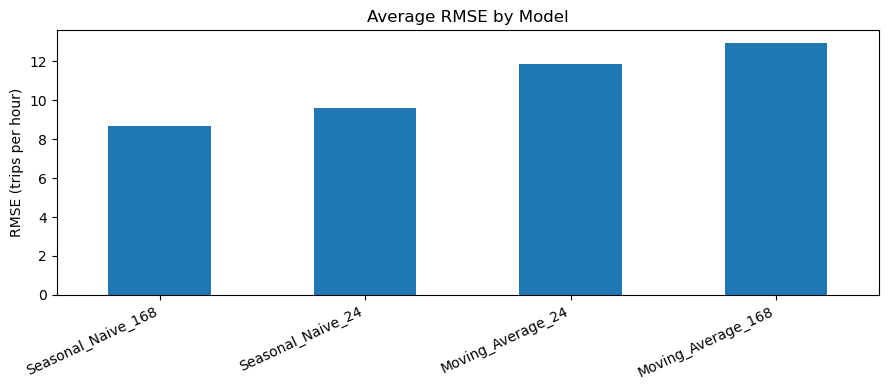

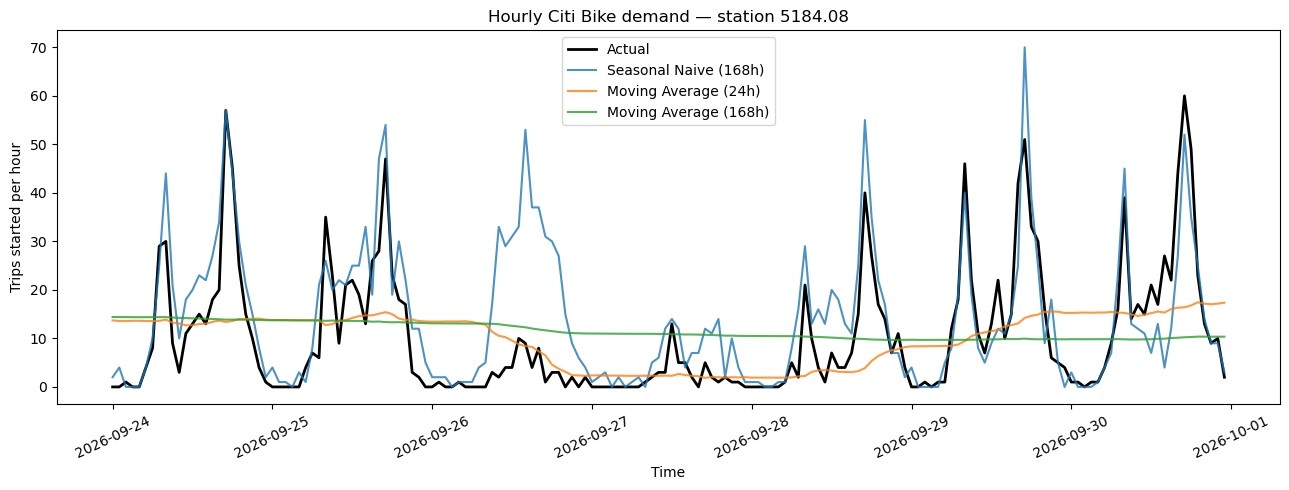

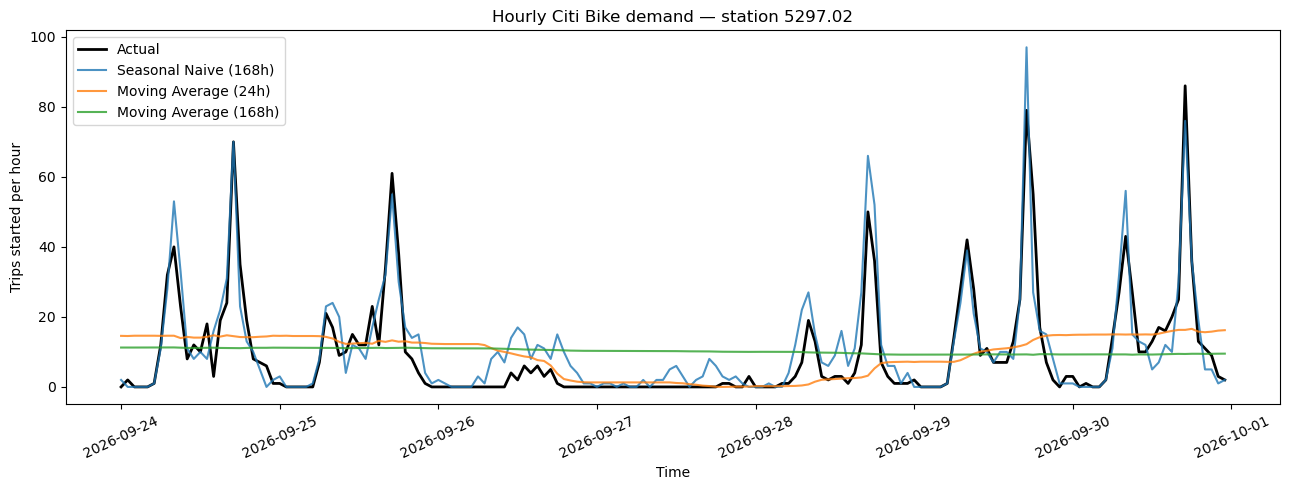

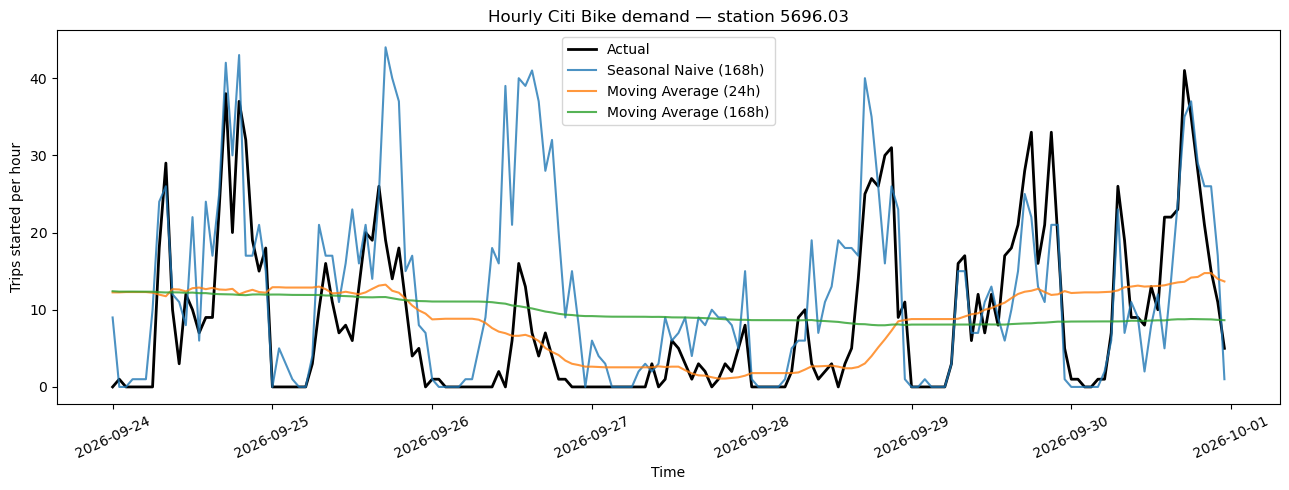

In [11]:
# RESULTS: comparison chart and actual-vs-predicted forecast plots
ax = comparison.set_index("model")["RMSE"].plot(kind="bar", figsize=(9, 4), title="Average RMSE by Model")
ax.set_ylabel("RMSE (trips per hour)")
ax.set_xlabel("")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(OUT / "model_rmse.png", dpi=160)
plt.show()

for station, g in predictions.groupby("station_id"):
    g = g.sort_values("timestamp")
    plt.figure(figsize=(13, 5))
    plt.plot(g["timestamp"], g["actual"], label="Actual", color="black", linewidth=2)
    plt.plot(g["timestamp"], g["Seasonal_Naive_168"], label="Seasonal Naive (168h)", alpha=.8)
    plt.plot(g["timestamp"], g["Moving_Average_24"], label="Moving Average (24h)", alpha=.8)
    plt.plot(g["timestamp"], g["Moving_Average_168"], label="Moving Average (168h)", alpha=.8)
    plt.title(f"Hourly Citi Bike demand — station {station}")
    plt.ylabel("Trips started per hour")
    plt.xlabel("Time")
    plt.legend()
    plt.xticks(rotation=25)
    plt.tight_layout()
    safe_id = ''.join(ch if ch.isalnum() or ch in '-_' else '_' for ch in str(station))
    plt.savefig(OUT / f"forecast_station_{safe_id}.png", dpi=160)
    plt.show()